# 06. Figuras e Tabelas da Dissertação
Este notebook gera, a partir dos dados da pesquisa, todas as figuras e as tabelas de apoio do texto da dissertação.

* As imagens **não têm título**: o título fica na legenda do documento.
* As figuras ficam em `resultados/figuras/dissertacao_texto/` e as tabelas, em `resultados/tabelas_dissertacao/texto/`.
* Sobra, déficit e custo são **potenciais**. A instituição não pesa o alimento descartado nem registra quem ficou sem refeição.
* O arquivo `numeros_texto.json` guarda os valores citados no texto.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from matplotlib.ticker import FuncFormatter

from src.core.config import GOLD, RESULTADOS, SEMENTE_ALEATORIA, SILVER
from src.core.models import definir_cenarios_features, obter_catalogo_modelos, avaliar_um_algoritmo
from src.core.safety_margins import POLITICA_IA, combinar_hibrido, prever_com_modelo_congelado
from src.core.selecao import carregar_selecao, nome_modelo

SELECAO = carregar_selecao()
ALG_T1, CEN_T1 = SELECAO["t1"]["algoritmo"], SELECAO["t1"]["cenario"]
ALG_T2, CEN_T2 = SELECAO["t2"]["algoritmo"], SELECAO["t2"]["cenario"]
NOME_T1, NOME_T2 = nome_modelo(ALG_T1), nome_modelo(ALG_T2)

PASTA_FIG = RESULTADOS / "figuras" / "dissertacao_texto"
PASTA_TAB = RESULTADOS / "tabelas_dissertacao" / "texto"
PASTA_FIG.mkdir(parents=True, exist_ok=True)
PASTA_TAB.mkdir(parents=True, exist_ok=True)

COR_IA, COR_NUTRI, COR_HIB, COR_RES = "#2563A8", "#C2570C", "#1E8A6E", "#7A4FA3"
COR_REAL, COR_NEUTRA, COR_GRADE = "#1F2933", "#8A94A0", "#E4E7EB"
COR_SOBRA, COR_DEFICIT = "#2563A8", "#C2570C"
PRECO_2026, PRECO_RESERVAS = 14.00, 17.36
DIAS = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta"]
MESES = {2: "Fev", 3: "Mar", 4: "Abr", 5: "Mai", 6: "Jun", 7: "Jul", 8: "Ago", 9: "Set", 10: "Out", 11: "Nov", 12: "Dez"}

plt.rcdefaults()
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": COR_NEUTRA, "axes.labelcolor": COR_REAL, "xtick.color": COR_REAL, "ytick.color": COR_REAL,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": COR_GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300, "lines.linewidth": 1.8
})


def br(valor, casas=2):
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def eixo_br(ax, eixo="y", casas=0):
    (ax.yaxis if eixo == "y" else ax.xaxis).set_major_formatter(FuncFormatter(lambda v, _: br(v, casas)))


def salvar(fig, nome):
    fig.savefig(PASTA_FIG / f"{nome}.png", bbox_inches="tight", facecolor="white")
    plt.show()


def metricas(y, p, preco=PRECO_2026):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    ss = ((y - y.mean()) ** 2).sum()
    sobra, deficit = float(np.maximum(e, 0).sum()), float(np.maximum(-e, 0).sum())
    return {
        "n": len(y), "MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean()), "WAPE": np.abs(e).sum() / y.sum() * 100,
        "R2": 1 - (e ** 2).sum() / ss, "Sobra": sobra, "Deficit": deficit, "Dias_deficit": int((e < 0).sum()),
        "Dias_deficit_pct": (e < 0).mean() * 100, "Custo": sobra * preco
    }


fato = pd.read_parquet(SILVER / "silver_fato_diaria.parquet")
g1 = pd.read_parquet(GOLD / "gold_t1.parquet")
g2 = pd.read_parquet(GOLD / "gold_t2.parquet")
preds = pd.read_parquet(RESULTADOS / "modelos" / "predicoes_detalhadas_torneio.parquet")
preds["data"] = pd.to_datetime(preds["data"])
cong = pd.read_parquet(RESULTADOS / "modelos" / "predicoes_congelado_set_out.parquet")
servidos = fato[fato["consumo"].notna() & (fato["dia_semana"] < 5)].copy()
h = servidos[servidos["ano"] <= 2025].copy()
a26 = servidos[servidos["ano"] == 2026].copy()
ATIP = set(fato.loc[fato["status_consumo"].eq("atipico"), "data"])
NUM = {}
print(len(h), len(a26), len(ATIP))

500 156 5


## 1. Tabelas de apoio

In [2]:
# Regimes de planejamento, ano a ano
linhas = []
pares = fato[fato["consumo"].notna()]
for ano, col, nome, preco in [(2023, "reserva_discente", "Reservas discentes", PRECO_RESERVAS), (2024, "reserva_discente", "Reservas discentes", PRECO_RESERVAS),
                              (2025, "reserva_discente", "Reservas discentes", PRECO_RESERVAS), (2026, "plano_nutricionista", "Quantitativo institucional", PRECO_2026)]:
    s = pares[(pares["ano"] == ano) & pares[col].notna()]
    linhas.append({"Ano": ano, "Regime": nome, "Consumo_medio": s["consumo"].mean(), "Planejado_medio": s[col].mean(),
                   "Saldo": (s[col] - s["consumo"]).sum(), **metricas(s["consumo"], s[col], preco)})
s_res = pares[pares["reserva_discente"].notna()]
s_nut = pares[pares["plano_nutricionista"].notna()]
s_nfa = s_nut[s_nut["data"] <= "2026-08-31"]
regimes = pd.DataFrame(linhas)
regimes.to_csv(PASTA_TAB / "planejamento_por_ano.csv", sep=";", index=False)
NUM["regime_reservas"] = metricas(s_res["consumo"], s_res["reserva_discente"], PRECO_RESERVAS)
NUM["regime_reservas"]["r"] = s_res["consumo"].corr(s_res["reserva_discente"])
NUM["regime_reservas"]["saldo"] = float((s_res["reserva_discente"] - s_res["consumo"]).sum())
NUM["regime_nutri"] = metricas(s_nut["consumo"], s_nut["plano_nutricionista"])
NUM["regime_nutri"]["r"] = s_nut["consumo"].corr(s_nut["plano_nutricionista"])
NUM["regime_nutri"]["saldo"] = float((s_nut["plano_nutricionista"] - s_nut["consumo"]).sum())
NUM["regime_nutri_fev_ago"] = metricas(s_nfa["consumo"], s_nfa["plano_nutricionista"])

# Torneio em Fev-Ago
FAMILIAS = {"Regressao_Linear": "Linear", "Ridge": "Linear", "Lasso": "Linear", "ElasticNet": "Linear",
            "Ensemble_Bagging_RandomForest": "Bagging", "Ensemble_Bagging_ExtraTrees": "Bagging", "Ensemble_Bagging_Arvores": "Bagging",
            "KNN": "Vizinhança", "SVR": "Vetores de suporte", "Arvore_Decisao": "Árvore de decisão", "MLP": "Rede neural",
            "Ensemble_Boosting_Gradient": "Boosting", "Ensemble_Boosting_AdaBoost": "Boosting", "Ensemble_Boosting_LightGBM": "Boosting",
            "Ensemble_Boosting_XGBoost": "Boosting", "Ensemble_Boosting_CatBoost": "Boosting",
            "Ensemble_Voting_Heterogeneo": "Voting", "Ensemble_Stacking_MetaModel": "Stacking", "Ensemble_Blending_Holdout": "Blending",
            "Ensemble_Cascading_Estagios": "Cascading", "Baseline_Nivel_Recente_10d": "Referência simples", "Baseline_Mesmo_Dia_Semana": "Referência simples"}
NOMES = {"Ensemble_Bagging_Arvores": "Bagging de Árvores", "Arvore_Decisao": "Árvore de Decisão", "MLP": "Rede Neural MLP", "Regressao_Linear": "Regressão Linear", "ElasticNet": "Elastic Net", "Ensemble_Bagging_RandomForest": "Random Forest", "Ensemble_Bagging_ExtraTrees": "ExtraTrees",
         "Ensemble_Boosting_Gradient": "Gradient Boosting", "Ensemble_Boosting_AdaBoost": "AdaBoost", "Ensemble_Boosting_LightGBM": "LightGBM",
         "Ensemble_Boosting_XGBoost": "XGBoost", "Ensemble_Boosting_CatBoost": "CatBoost", "Ensemble_Voting_Heterogeneo": "Voting",
         "Ensemble_Stacking_MetaModel": "Stacking", "Ensemble_Blending_Holdout": "Blending", "Ensemble_Cascading_Estagios": "Cascading",
         "Baseline_Nivel_Recente_10d": "Nível recente (10 dias)", "Baseline_Mesmo_Dia_Semana": "Mesmo dia da semana"}
CEN = {"Cenario_1_Base_Cardapio": "C1", "Cenario_2_Com_Cardapio": "C2", "Cenario_3_Com_Clima": "C3", "Cenario_4_Com_Nutricionista": "C4"}
fa = preds[(preds["data"] >= "2026-02-01") & (preds["data"] <= "2026-08-31")]
so = preds[preds["data"] >= "2026-09-01"]
linhas = []
for (hz, cen, alg), d in fa.groupby(["horizonte", "cenario", "algoritmo"]):
    linhas.append({"Horizonte": "T+1" if hz == "t1" else "T+2", "Cenario": CEN[cen], "Modelo": NOMES.get(alg, alg), "Familia": FAMILIAS[alg], **metricas(d["consumo_real"], d["previsao"])})
torneio = pd.DataFrame(linhas).sort_values(["Horizonte", "MAE"])
torneio.to_csv(PASTA_TAB / "torneio_fev_ago_completo.csv", sep=";", index=False)
ml = torneio[torneio["Familia"] != "Referência simples"]
top_t1, top_t2 = (ml[ml["Horizonte"] == hz].head(10).reset_index(drop=True) for hz in ("T+1", "T+2"))
top_t1.to_csv(PASTA_TAB / "top10_t1.csv", sep=";", index=False)
top_t2.to_csv(PASTA_TAB / "top10_t2.csv", sep=";", index=False)
cenarios = torneio.sort_values("MAE").groupby(["Horizonte", "Cenario"], as_index=False).first().sort_values(["Horizonte", "Cenario"])
cenarios.to_csv(PASTA_TAB / "melhor_por_cenario.csv", sep=";", index=False)
familias = ml[ml["Horizonte"] == "T+1"].sort_values("MAE").groupby("Familia", as_index=False).first().sort_values("MAE")
familias.to_csv(PASTA_TAB / "melhor_por_familia_t1.csv", sep=";", index=False)
ref_c = torneio[(torneio["Modelo"] == NOME_T1) & (torneio["Horizonte"] == "T+1")].set_index("Cenario")
ref_c.to_csv(PASTA_TAB / "modelo_base_por_cenario_t1.csv", sep=";")
NUM["n_configuracoes"] = int(len(torneio))
display(top_t1.round(2)); display(top_t2.round(2)); display(cenarios.round(2))

,Horizonte,Cenario,Modelo,Familia,n,MAE,RMSE,WAPE,R2,Sobra,Deficit,Dias_deficit,Dias_deficit_pct,Custo
0,T+1,C4,Lasso,Linear,123,23.27,34.26,13.91,0.52,1584.0,1278.0,71,57.72,22176.0
1,T+1,C4,Elastic Net,Linear,123,23.30,33.71,13.93,0.54,1446.0,1420.0,77,62.60,20244.0
2,T+1,C4,Ridge,Linear,123,24.25,33.51,14.50,0.54,1297.0,1686.0,80,65.04,18158.0
3,T+1,C4,Voting,Voting,123,24.35,35.77,14.56,0.48,1562.0,1433.0,71,57.72,21868.0
4,T+1,C4,ExtraTrees,Bagging,123,26.21,39.20,15.67,0.37,1768.0,1456.0,65,52.85,24752.0
5,T+1,C4,Regressão Linear,Linear,123,26.24,36.54,15.69,0.46,1339.0,1888.0,81,65.85,18746.0
6,T+1,C4,LightGBM,Boosting,123,26.54,39.23,15.87,0.37,1872.0,1393.0,65,52.85,26208.0
7,T+1,C4,Gradient Boosting,Boosting,123,26.68,38.83,15.96,0.39,1838.0,1444.0,64,52.03,25732.0
8,T+1,C4,Random Forest,Bagging,123,26.76,39.52,16.00,0.36,1912.0,1380.0,62,50.41,26768.0
9,T+1,C4,XGBoost,Boosting,123,26.91,39.62,16.09,0.36,1918.0,1392.0,66,53.66,26852.0


,Horizonte,Cenario,Modelo,Familia,n,MAE,RMSE,WAPE,R2,Sobra,Deficit,Dias_deficit,Dias_deficit_pct,Custo
0,T+2,C1,ExtraTrees,Bagging,123,27.93,42.28,16.70,0.27,1708.0,1727.0,70,56.91,23912.0
1,T+2,C2,Voting,Voting,123,28.02,41.35,16.76,0.30,1677.0,1770.0,76,61.79,23478.0
2,T+2,C2,ExtraTrees,Bagging,123,28.18,43.05,16.85,0.25,1778.0,1688.0,68,55.28,24892.0
3,T+2,C3,ExtraTrees,Bagging,123,28.47,42.91,17.02,0.25,1767.0,1735.0,72,58.54,24738.0
4,T+2,C2,Lasso,Linear,123,28.60,40.99,17.10,0.32,1745.0,1773.0,69,56.10,24430.0
5,T+2,C1,Voting,Voting,123,28.75,42.29,17.19,0.27,1636.0,1900.0,77,62.60,22904.0
6,T+2,C3,Voting,Voting,123,28.87,41.86,17.26,0.29,1620.0,1931.0,78,63.41,22680.0
7,T+2,C3,AdaBoost,Boosting,123,28.90,42.29,17.28,0.27,1864.0,1691.0,67,54.47,26096.0
8,T+2,C2,AdaBoost,Boosting,123,28.96,42.12,17.32,0.28,1821.0,1741.0,70,56.91,25494.0
9,T+2,C3,Lasso,Linear,123,28.96,41.29,17.32,0.31,1731.0,1831.0,72,58.54,24234.0


,Horizonte,Cenario,Modelo,Familia,n,MAE,RMSE,WAPE,R2,Sobra,Deficit,Dias_deficit,Dias_deficit_pct,Custo
0,T+1,C1,ExtraTrees,Bagging,123,27.85,41.07,16.66,0.31,1769.0,1657.0,67,54.47,24766.0
1,T+1,C2,Voting,Voting,123,27.40,39.37,16.38,0.37,1671.0,1699.0,72,58.54,23394.0
2,T+1,C3,Voting,Voting,123,27.36,39.00,16.36,0.38,1695.0,1670.0,70,56.91,23730.0
3,T+1,C4,Lasso,Linear,123,23.27,34.26,13.91,0.52,1584.0,1278.0,71,57.72,22176.0
4,T+2,C1,ExtraTrees,Bagging,123,27.93,42.28,16.70,0.27,1708.0,1727.0,70,56.91,23912.0
5,T+2,C2,Voting,Voting,123,28.02,41.35,16.76,0.30,1677.0,1770.0,76,61.79,23478.0
6,T+2,C3,ExtraTrees,Bagging,123,28.47,42.91,17.02,0.25,1767.0,1735.0,72,58.54,24738.0


In [3]:
# Retrospectivo e prospectivo: políticas do T+1
base_fa = fa[(fa["horizonte"] == "t1") & (fa["cenario"] == CEN_T1) & (fa["algoritmo"] == ALG_T1)].sort_values("data")
base_fa = base_fa.merge(fato[["data", "plano_nutricionista"]], on="data")
y, ia, nu = base_fa["consumo_real"].values, base_fa["previsao"].values, base_fa["plano_nutricionista"].values
hi = combinar_hibrido(ia, nu)
marg = pd.read_csv(RESULTADOS / "tabelas_dissertacao" / "tabela_09_margens_empiricas_quantis.csv", sep=";")
m = {(r["Politica"], r["Quantil"]): r["Margem_ref"] for _, r in marg.iterrows()}
MIA, MHI = POLITICA_IA, "Modelo Híbrido 50/50"
pol_defs = [("Nutricionista", nu, 0), (NOME_T1, ia, 0), ("Híbrido 50/50", hi, 0)]
for q in ("P75", "P85", "P90"):
    pol_defs += [(f"{NOME_T1} + {q}", ia, m[(MIA, q)]), (f"Híbrido + {q}", hi, m[(MHI, q)])]
retro = pd.DataFrame([{"Politica": n, "Margem": mg, **metricas(y, p + mg)} for n, p, mg in pol_defs])
retro.to_csv(PASTA_TAB / "retro_politicas.csv", sep=";", index=False)

te = cong.sort_values("data").copy()
te["sem_evento"] = ~te["evento_registrado"]
linhas = []
for recorte, s in (("33 dias", te), ("28 dias sem evento", te[te["sem_evento"]]), ("5 dias de enchente", te[te["eh_crise_climatica"]]),
                   ("Setembro", te[te["data"].dt.month == 9]), ("Outubro", te[te["data"].dt.month == 10])):
    for nome, p, mg in [("Nutricionista", s["plano_nutricionista"], 0), (f"{NOME_T1} congelado", s["previsao_ia"], 0), ("Híbrido congelado", s["previsao_hibrido"], 0),
                        ("Híbrido + P85", s["previsao_hibrido"], m[(MHI, "P85")]), (f"{NOME_T1} + P85", s["previsao_ia"], m[(MIA, "P85")])]:
        linhas.append({"Recorte": recorte, "Metodo": nome, **metricas(s["consumo"], p + mg)})
prosp = pd.DataFrame(linhas)
prosp.to_csv(PASTA_TAB / "prospectivo_metodos.csv", sep=";", index=False)

# T+2 no período prospectivo
cols2 = [c for c in definir_cenarios_features()[CEN_T2] if c in g2.columns]
t2 = prever_com_modelo_congelado(g2, cols2, ALG_T2)
t2["ev"] = t2["data"].isin(ATIP)
ret_t2 = fa[(fa["horizonte"] == "t2") & (fa["cenario"] == CEN_T2) & (fa["algoritmo"] == ALG_T2)]
marg_t2 = float(max(0, np.ceil(np.quantile(ret_t2["consumo_real"] - ret_t2["previsao"], 0.85))))
pt2 = pd.DataFrame([
    {"Recorte": "Fev-Ago (walk-forward)", "Metodo": NOME_T2, **metricas(ret_t2["consumo_real"], ret_t2["previsao"])},
    {"Recorte": "Set-Out, 33 dias", "Metodo": f"{NOME_T2} congelado", **metricas(t2["consumo"], t2["previsao_ia"])},
    {"Recorte": "Set-Out, 28 dias", "Metodo": f"{NOME_T2} congelado", **metricas(t2.loc[~t2["ev"], "consumo"], t2.loc[~t2["ev"], "previsao_ia"])},
    {"Recorte": "Set-Out, 33 dias", "Metodo": f"{NOME_T2} + P85", **metricas(t2["consumo"], t2["previsao_ia"] + marg_t2)}
])
pt2.to_csv(PASTA_TAB / "t2_compras.csv", sep=";", index=False)
NUM["margem_t2_p85"] = marg_t2

# Sensibilidade à janela de treino em Fev-Ago
from src.core.models import LIMITES_ALVO, arredondar_refeicoes
cols = [c for c in definir_cenarios_features()[CEN_T1] if c in g1.columns]
alvo = g1[(g1["data"] >= "2026-02-01") & (g1["data"] <= "2026-08-31") & g1["consumo"].notna()]
linhas = []
for meses, rotulo in ((6, "6 meses"), (12, "12 meses"), (24, "24 meses"), (None, "Todo o histórico")):
    saidas = []
    for o, a in alvo.groupby("origem"):
        tr = g1[(g1["data"] < o) & g1["usar_no_treino"] & g1["consumo"].notna() & g1["alvo_relativo"].notna()]
        if meses:
            tr = tr[tr["data"] >= o - pd.DateOffset(months=meses)]
        modelo = obter_catalogo_modelos()[ALG_T1]["construtor"]()
        modelo.fit(tr[cols], tr["alvo_relativo"].clip(*LIMITES_ALVO))
        saidas.append(a.assign(p=arredondar_refeicoes(np.clip(modelo.predict(a[cols]), *LIMITES_ALVO) * a["nivel_base"].values)))
    s = pd.concat(saidas)
    linhas.append({"Janela": rotulo, **metricas(s["consumo"], s["p"])})
janelas = pd.DataFrame(linhas)
janelas.to_csv(PASTA_TAB / "sensibilidade_janela_treino.csv", sep=";", index=False)
display(retro.round(2)); display(prosp.round(2)); display(pt2.round(2)); display(janelas.round(2))

,Politica,Margem,n,MAE,RMSE,WAPE,R2,Sobra,Deficit,Dias_deficit,Dias_deficit_pct,Custo
0,Nutricionista,0.0,123,26.21,39.45,15.67,0.37,2561.0,663.0,48,39.02,35854.0
1,Ridge,0.0,123,27.48,37.54,16.43,0.43,1437.0,1943.0,75,60.98,20118.0
2,Híbrido 50/50,0.0,123,22.08,33.39,13.20,0.55,1723.0,993.0,65,52.85,24122.0
3,Ridge + P75,24.0,123,29.53,42.28,17.66,0.27,3039.0,593.0,31,25.20,42546.0
4,Híbrido + P75,14.0,123,25.54,38.43,15.27,0.40,2797.0,345.0,31,25.20,39158.0
5,Ridge + P85,34.0,123,35.35,47.81,21.14,0.07,4012.0,336.0,17,13.82,56168.0
6,Híbrido + P85,21.0,123,29.63,42.48,17.72,0.26,3479.0,166.0,17,13.82,48706.0
7,Ridge + P90,42.0,123,41.40,53.18,24.75,-0.15,4876.0,216.0,12,9.76,68264.0
8,Híbrido + P90,25.0,123,32.64,45.13,19.52,0.17,3910.0,105.0,12,9.76,54740.0


,Recorte,Metodo,n,MAE,RMSE,WAPE,R2,Sobra,Deficit,Dias_deficit,Dias_deficit_pct,Custo
0,33 dias,Nutricionista,33,39.48,65.46,21.90,-0.58,972.0,331.0,11,33.33,13608.0
1,33 dias,Ridge congelado,33,34.79,54.83,19.30,-0.11,591.0,557.0,20,60.61,8274.0
2,33 dias,Híbrido congelado,33,34.61,59.07,19.20,-0.29,744.0,398.0,15,45.45,10416.0
3,33 dias,Híbrido + P85,33,42.58,66.11,23.62,-0.61,1222.0,183.0,5,15.15,17108.0
4,33 dias,Ridge + P85,33,43.21,65.05,23.97,-0.56,1291.0,135.0,5,15.15,18074.0
5,28 dias sem evento,Nutricionista,28,22.14,30.46,11.10,-1.71,289.0,331.0,11,39.29,4046.0
6,28 dias sem evento,Ridge congelado,28,22.71,30.77,11.38,-1.76,79.0,557.0,20,71.43,1106.0
7,28 dias sem evento,Híbrido congelado,28,19.39,28.44,9.72,-1.36,145.0,398.0,15,53.57,2030.0
8,28 dias sem evento,Híbrido + P85,28,25.04,29.51,12.55,-1.54,518.0,183.0,5,17.86,7252.0
9,28 dias sem evento,Ridge + P85,28,26.57,30.69,13.32,-1.75,609.0,135.0,5,17.86,8526.0


,Recorte,Metodo,n,MAE,RMSE,WAPE,R2,Sobra,Deficit,Dias_deficit,Dias_deficit_pct,Custo
0,Fev-Ago (walk-forward),ExtraTrees,123,27.93,42.28,16.70,0.27,1708.0,1727.0,70,56.91,23912.0
1,"Set-Out, 33 dias",ExtraTrees congelado,33,33.33,54.01,18.49,-0.08,633.0,467.0,21,63.64,8862.0
2,"Set-Out, 28 dias",ExtraTrees congelado,28,19.46,22.56,9.75,-0.49,78.0,467.0,21,75.00,1092.0
3,"Set-Out, 33 dias",ExtraTrees + P85,33,41.58,67.64,23.06,-0.69,1363.0,9.0,4,12.12,19082.0


,Janela,n,MAE,RMSE,WAPE,R2,Sobra,Deficit,Dias_deficit,Dias_deficit_pct,Custo
0,6 meses,123,36.96,55.07,22.10,-0.24,2795.0,1751.0,68,55.28,39130.0
1,12 meses,123,27.48,37.54,16.43,0.43,1437.0,1943.0,75,60.98,20118.0
2,24 meses,123,29.83,40.45,17.84,0.33,1694.0,1975.0,73,59.35,23716.0
3,Todo o histórico,123,28.22,38.41,16.87,0.40,1581.0,1890.0,73,59.35,22134.0


## 2. Figuras do percurso e do artefato

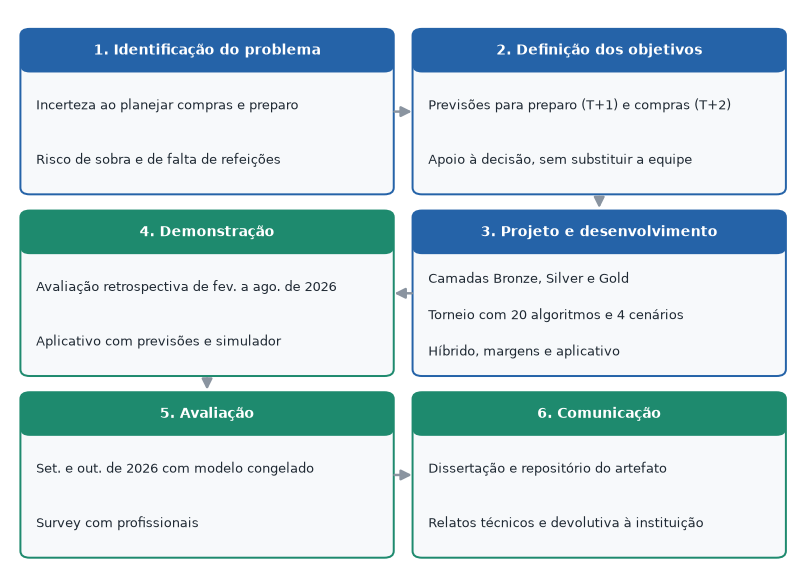

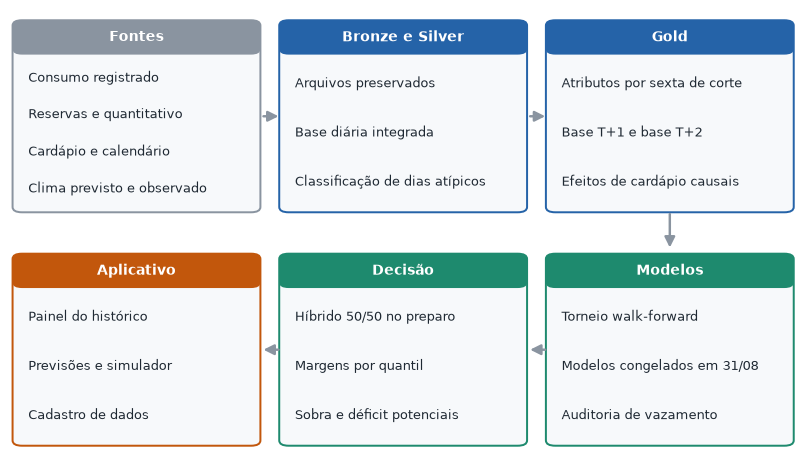

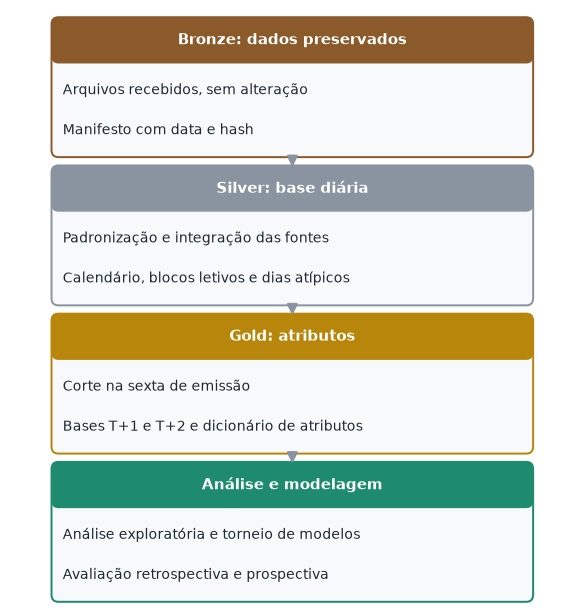

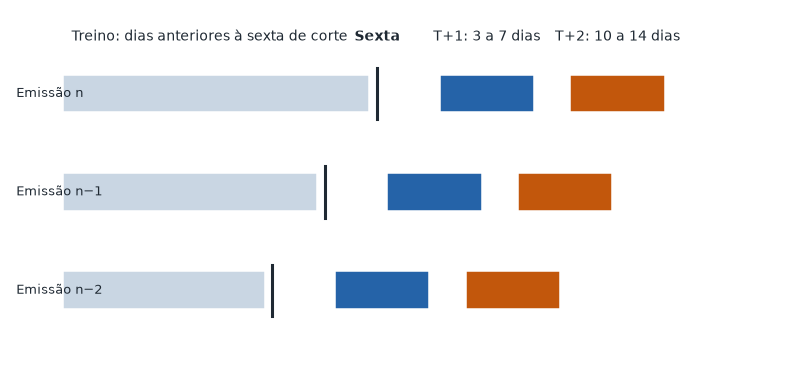

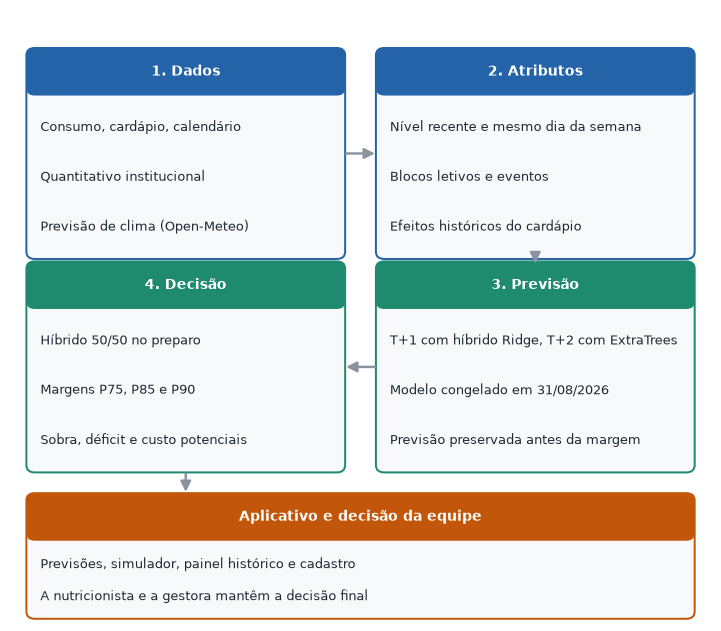

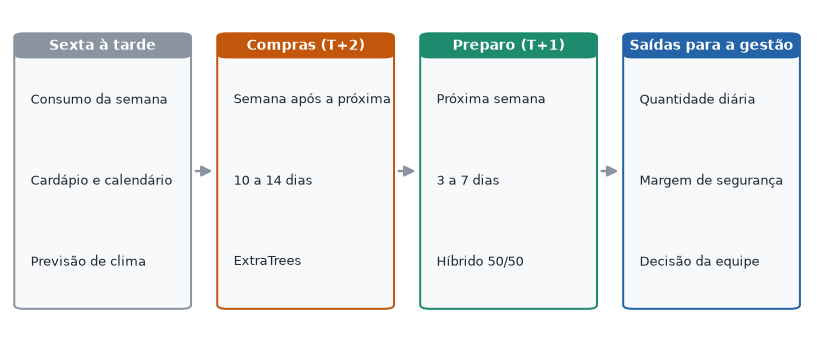

In [4]:
def caixa(ax, x, y, w, h, titulo, linhas=(), cor=COR_IA, tam=8.2):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.008,rounding_size=0.012", fc="#F7F9FB", ec=cor, lw=1.3, transform=ax.transAxes))
    ax.add_patch(FancyBboxPatch((x, y + h - 0.062), w, 0.062, boxstyle="round,pad=0.008,rounding_size=0.012", fc=cor, ec=cor, lw=0, transform=ax.transAxes))
    ax.text(x + w / 2, y + h - 0.031, titulo, ha="center", va="center", color="white", fontsize=tam + 0.7, fontweight="bold", transform=ax.transAxes)
    passo = (h - 0.085) / max(len(linhas), 1)
    for i, l in enumerate(linhas):
        ax.text(x + 0.012, y + h - 0.085 - passo * (i + 0.45), l, ha="left", va="center", color=COR_REAL, fontsize=tam, transform=ax.transAxes)


def seta(ax, a, b, cor=COR_NEUTRA):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle="-|>", mutation_scale=14, lw=1.6, color=cor, transform=ax.transAxes))


def tela(l=9.2, a=6.4):
    fig, ax = plt.subplots(figsize=(l, a))
    ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    return fig, ax


# Figura 1: DSR
fig, ax = tela(9.2, 6.6)
wc, hc = 0.46, 0.28
etapas = [
    (0.02, 0.68, "1. Identificação do problema", ["Incerteza ao planejar compras e preparo", "Risco de sobra e de falta de refeições"]),
    (0.52, 0.68, "2. Definição dos objetivos", ["Previsões para preparo (T+1) e compras (T+2)", "Apoio à decisão, sem substituir a equipe"]),
    (0.52, 0.355, "3. Projeto e desenvolvimento", ["Camadas Bronze, Silver e Gold", "Torneio com 20 algoritmos e 4 cenários", "Híbrido, margens e aplicativo"]),
    (0.02, 0.355, "4. Demonstração", ["Avaliação retrospectiva de fev. a ago. de 2026", "Aplicativo com previsões e simulador"]),
    (0.02, 0.03, "5. Avaliação", ["Set. e out. de 2026 com modelo congelado", "Survey com profissionais"]),
    (0.52, 0.03, "6. Comunicação", ["Dissertação e repositório do artefato", "Relatos técnicos e devolutiva à instituição"]),
]
for x, y0, t, ls in etapas:
    caixa(ax, x, y0, wc, hc, t, ls, COR_IA if t[0] in "123" else COR_HIB, 8.4)
seta(ax, (0.485, 0.82), (0.515, 0.82)); seta(ax, (0.75, 0.673), (0.75, 0.642)); seta(ax, (0.515, 0.495), (0.485, 0.495))
seta(ax, (0.25, 0.348), (0.25, 0.317)); seta(ax, (0.485, 0.17), (0.515, 0.17))
salvar(fig, "figura_01_dsr")

# Figura 2: dados ao apoio à decisão
fig, ax = tela(9.2, 5.2)
wc, hc = 0.30, 0.42
for x, y0, t, ls, c in [
    (0.01, 0.55, "Fontes", ["Consumo registrado", "Reservas e quantitativo", "Cardápio e calendário", "Clima previsto e observado"], COR_NEUTRA),
    (0.35, 0.55, "Bronze e Silver", ["Arquivos preservados", "Base diária integrada", "Classificação de dias atípicos"], COR_IA),
    (0.69, 0.55, "Gold", ["Atributos por sexta de corte", "Base T+1 e base T+2", "Efeitos de cardápio causais"], COR_IA),
    (0.69, 0.02, "Modelos", ["Torneio walk-forward", "Modelos congelados em 31/08", "Auditoria de vazamento"], COR_HIB),
    (0.35, 0.02, "Decisão", ["Híbrido 50/50 no preparo", "Margens por quantil", "Sobra e déficit potenciais"], COR_HIB),
    (0.01, 0.02, "Aplicativo", ["Painel do histórico", "Previsões e simulador", "Cadastro de dados"], COR_NUTRI),
]:
    caixa(ax, x, y0, wc, hc, t, ls, c, 8.3)
seta(ax, (0.318, 0.76), (0.345, 0.76)); seta(ax, (0.658, 0.76), (0.685, 0.76)); seta(ax, (0.84, 0.545), (0.84, 0.455))
seta(ax, (0.685, 0.23), (0.658, 0.23)); seta(ax, (0.345, 0.23), (0.318, 0.23))
salvar(fig, "figura_02_arquitetura_dados")

# Figura 3: camadas
fig, ax = tela(6.6, 7.0)
for y0, t, ls, c in [
    (0.76, "Bronze: dados preservados", ["Arquivos recebidos, sem alteração", "Manifesto com data e hash"], "#8A5A2B"),
    (0.51, "Silver: base diária", ["Padronização e integração das fontes", "Calendário, blocos letivos e dias atípicos"], COR_NEUTRA),
    (0.26, "Gold: atributos", ["Corte na sexta de emissão", "Bases T+1 e T+2 e dicionário de atributos"], "#B8860B"),
    (0.01, "Análise e modelagem", ["Análise exploratória e torneio de modelos", "Avaliação retrospectiva e prospectiva"], COR_HIB),
]:
    caixa(ax, 0.08, y0, 0.84, 0.22, t, ls, c, 9)
for y0 in (0.752, 0.502, 0.252):
    seta(ax, (0.5, y0), (0.5, y0 - 0.022))
salvar(fig, "figura_03_camadas")

# Figura 4: validação temporal
fig, ax = plt.subplots(figsize=(9.2, 4.2))
ax.axis("off"); ax.set_xlim(-14, 16); ax.set_ylim(-0.3, 4.4)
for i, (dx, rot) in enumerate([(0, "Emissão n"), (-1, "Emissão n−1"), (-2, "Emissão n−2")]):
    y0 = 3.3 - i * 1.3
    x0 = dx * 2
    ax.barh(y0, 12 + x0 - 0.3, left=-12 - 0.0, height=0.5, color="#C9D6E3", edgecolor="white")
    ax.text(-13.8, y0, rot, va="center", ha="left", fontsize=8.5, color=COR_REAL)
    ax.barh(y0, 3.6, left=x0 + 2.4, height=0.5, color=COR_IA, edgecolor="white")
    ax.barh(y0, 3.6, left=x0 + 7.4, height=0.5, color=COR_NUTRI, edgecolor="white")
    ax.plot([x0, x0], [y0 - 0.34, y0 + 0.34], color=COR_REAL, lw=2)
ax.text(-6.4, 4.0, "Treino: dias anteriores à sexta de corte", ha="center", fontsize=9, color=COR_REAL)
ax.text(0, 4.0, "Sexta", ha="center", fontsize=9, fontweight="bold", color=COR_REAL)
ax.text(4.2, 4.0, "T+1: 3 a 7 dias", ha="center", fontsize=9, color=COR_REAL)
ax.text(9.2, 4.0, "T+2: 10 a 14 dias", ha="center", fontsize=9, color=COR_REAL)
salvar(fig, "figura_04_validacao_temporal")

# Figura 5: arquitetura sistêmica
fig, ax = tela(8.2, 7.2)
for x, y0, t, ls, c in [
    (0.03, 0.60, "1. Dados", ["Consumo, cardápio, calendário", "Quantitativo institucional", "Previsão de clima (Open-Meteo)"], COR_IA),
    (0.53, 0.60, "2. Atributos", ["Nível recente e mesmo dia da semana", "Blocos letivos e eventos", "Efeitos históricos do cardápio"], COR_IA),
    (0.53, 0.25, "3. Previsão", [f"T+1 com híbrido {NOME_T1}, T+2 com {NOME_T2}", "Modelo congelado em 31/08/2026", "Previsão preservada antes da margem"], COR_HIB),
    (0.03, 0.25, "4. Decisão", ["Híbrido 50/50 no preparo", "Margens P75, P85 e P90", "Sobra, déficit e custo potenciais"], COR_HIB),
]:
    caixa(ax, x, y0, 0.44, 0.33, t, ls, c, 8.6)
caixa(ax, 0.03, 0.01, 0.94, 0.19, "Aplicativo e decisão da equipe", ["Previsões, simulador, painel histórico e cadastro", "A nutricionista e a gestora mantêm a decisão final"], COR_NUTRI, 8.6)
seta(ax, (0.475, 0.765), (0.525, 0.765)); seta(ax, (0.75, 0.595), (0.75, 0.585)); seta(ax, (0.525, 0.415), (0.475, 0.415)); seta(ax, (0.25, 0.245), (0.25, 0.205))
salvar(fig, "figura_05_arquitetura_artefato")

# Figura 6: fluxo semanal
fig, ax = tela(9.6, 3.8)
LARG, PASSO, X0 = 0.2, 0.248, 0.012
for i, (t_, ls, c) in enumerate([
    ("Sexta à tarde", ["Consumo da semana", "Cardápio e calendário", "Previsão de clima"], COR_NEUTRA),
    ("Compras (T+2)", ["Semana após a próxima", "10 a 14 dias", NOME_T2], COR_NUTRI),
    ("Preparo (T+1)", ["Próxima semana", "3 a 7 dias", "Híbrido 50/50"], COR_HIB),
    ("Saídas para a gestão", ["Quantidade diária", "Margem de segurança", "Decisão da equipe"], COR_IA),
]):
    x = X0 + i * PASSO
    caixa(ax, x, 0.08, LARG, 0.84, t_, ls, c, 8.2)
    if i < 3:
        seta(ax, (x + LARG + 0.010, 0.5), (x + PASSO - 0.010, 0.5))
salvar(fig, "figura_06_fluxo_semanal")

## 3. Análise exploratória de 2023 a 2025

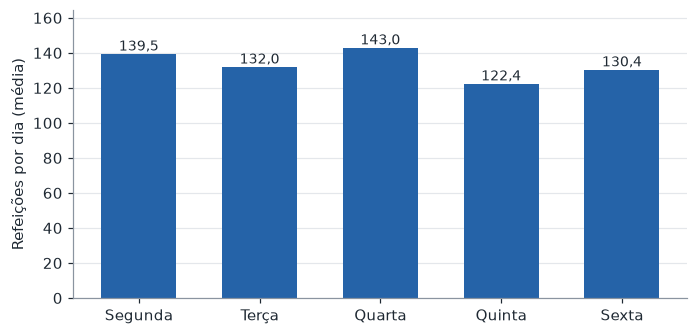

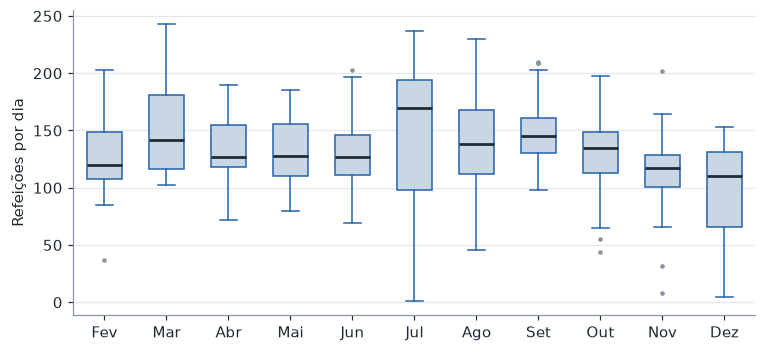

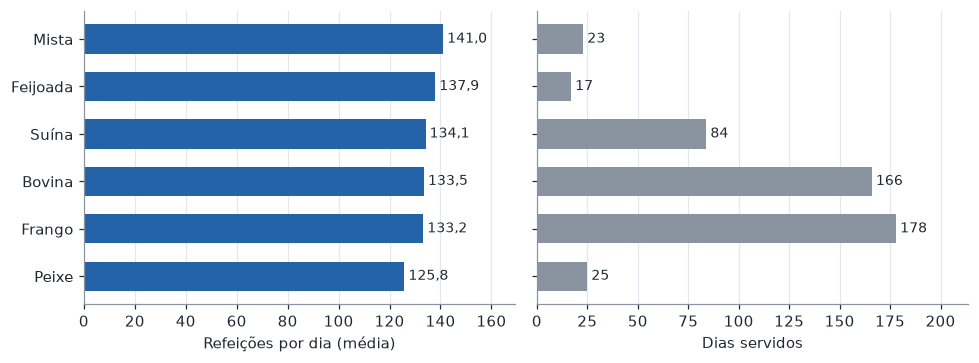

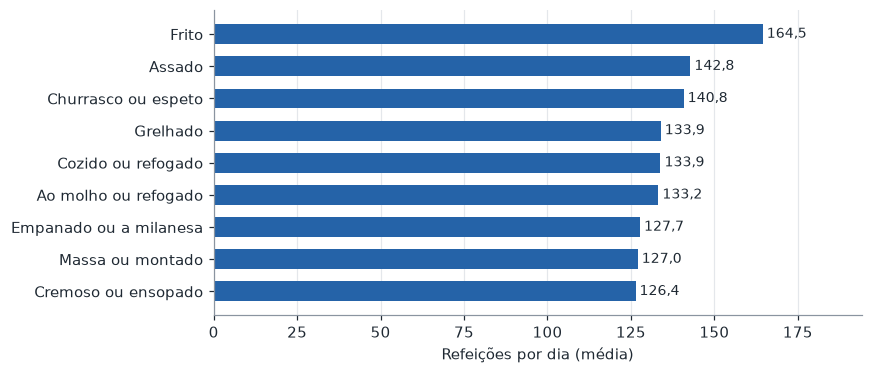

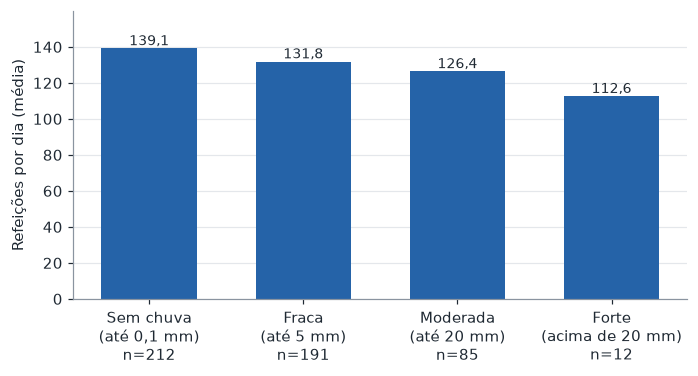

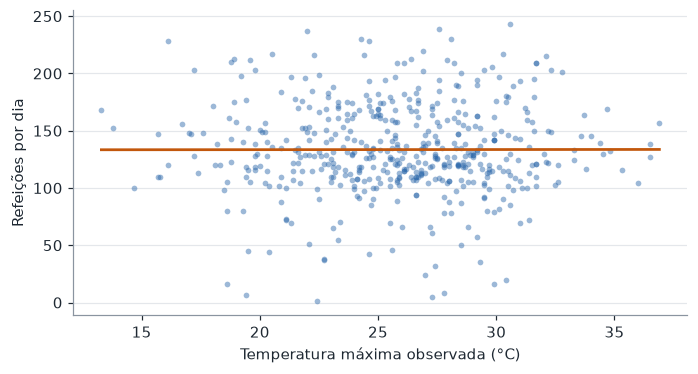

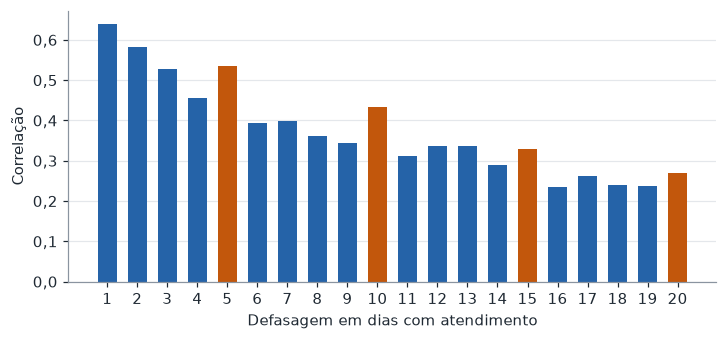

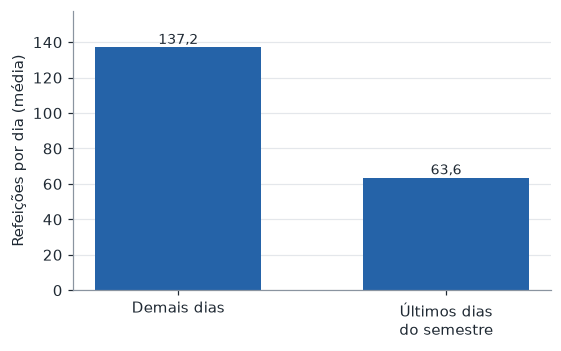

In [5]:
def barras(ax, rotulos, valores, cor=COR_IA, casas=1, horizontal=False):
    if horizontal:
        b = ax.barh(rotulos, valores, color=cor, height=0.62)
        ax.grid(False); ax.grid(axis="x", color=COR_GRADE)
        for r, v in zip(b, valores):
            ax.text(v, r.get_y() + r.get_height() / 2, " " + br(v, casas), va="center", fontsize=9, color=COR_REAL)
    else:
        b = ax.bar(rotulos, valores, color=cor, width=0.62)
        for r, v in zip(b, valores):
            ax.text(r.get_x() + r.get_width() / 2, v, br(v, casas), ha="center", va="bottom", fontsize=9, color=COR_REAL)
    return b


# Figura 7
dia_h = h.groupby("dia_semana")["consumo"].mean()
NUM["eda_dia_2325"] = dia_h.round(1).to_dict()
NUM["eda_n_2325"] = len(h)
NUM["eda_media_ano"] = servidos.groupby("ano")["consumo"].mean().round(1).to_dict()
NUM["eda_n_ano"] = servidos.groupby("ano").size().to_dict()
fig, ax = plt.subplots(figsize=(7.2, 3.4))
barras(ax, DIAS, dia_h.values); ax.set_ylabel("Refeições por dia (média)"); ax.set_ylim(0, dia_h.max() * 1.15)
salvar(fig, "figura_07_perfil_semanal_2023_2025")

# Figura 8
meses = [m_ for m_ in sorted(h["mes"].unique())]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.boxplot([h.loc[h["mes"] == m_, "consumo"] for m_ in meses], tick_labels=[MESES.get(m_, m_) for m_ in meses], widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#C9D6E3", edgecolor=COR_IA), medianprops=dict(color=COR_REAL, lw=1.8), whiskerprops=dict(color=COR_IA), capprops=dict(color=COR_IA),
           flierprops=dict(marker="o", ms=3, mfc=COR_NEUTRA, mec="none"))
ax.set_ylabel("Refeições por dia")
salvar(fig, "figura_08_sazonalidade_2023_2025")
NUM["eda_mes_2325"] = h.groupby("mes")["consumo"].mean().round(1).to_dict()

# Figura 9
prot = h[h["proteina"].notna()].groupby("proteina")["consumo"].agg(["mean", "size"]).sort_values("mean")
NUM["eda_proteina"] = prot.round(1).to_dict("index")
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
nomes_p = [p.capitalize().replace("Suina", "Suína") for p in prot.index]
barras(ax[0], nomes_p, prot["mean"].values, COR_IA, 1, True); ax[0].set_xlabel("Refeições por dia (média)"); ax[0].set_xlim(0, prot["mean"].max() * 1.2)
barras(ax[1], nomes_p, prot["size"].values, COR_NEUTRA, 0, True); ax[1].set_xlabel("Dias servidos"); ax[1].set_xlim(0, prot["size"].max() * 1.2)
fig.tight_layout(); salvar(fig, "figura_09_proteina_2023_2025")

# Figura 10
prep = h[h["preparo"].notna()].groupby("preparo")["consumo"].agg(["mean", "size"]).sort_values("mean")
NUM["eda_preparo"] = prep.round(1).to_dict("index")
fig, ax = plt.subplots(figsize=(7.6, 3.6))
barras(ax, [p.replace("_ou_", " ou ").replace("_a_", " à ").replace("_", " ").capitalize() for p in prep.index], prep["mean"].values, COR_IA, 1, True)
ax.set_xlabel("Refeições por dia (média)"); ax.set_xlim(0, prep["mean"].max() * 1.18)
salvar(fig, "figura_10_preparo_2023_2025")

# Figura 11
faixas = pd.cut(h["chuva_mm"], [-0.01, 0.1, 5, 20, 500], labels=["Sem chuva\n(até 0,1 mm)", "Fraca\n(até 5 mm)", "Moderada\n(até 20 mm)", "Forte\n(acima de 20 mm)"], right=False)
ch = h.groupby(faixas, observed=False)["consumo"].agg(["mean", "size"])
NUM["eda_chuva"] = {k.replace(chr(10), " "): v for k, v in ch.round(1).to_dict("index").items()}
fig, ax = plt.subplots(figsize=(7.2, 3.4))
barras(ax, [f"{i}\nn={int(n)}" for i, n in zip(ch.index, ch["size"])], ch["mean"].values); ax.set_ylabel("Refeições por dia (média)"); ax.set_ylim(0, ch["mean"].max() * 1.15)
salvar(fig, "figura_11_chuva_2023_2025")

# Figura 12
fig, ax = plt.subplots(figsize=(7.2, 3.6))
v = h.dropna(subset=["temp_max", "consumo"])
ax.scatter(v["temp_max"], v["consumo"], s=14, color=COR_IA, alpha=0.45, linewidths=0)
coef = np.polyfit(v["temp_max"], v["consumo"], 1); xs = np.array([v["temp_max"].min(), v["temp_max"].max()])
ax.plot(xs, np.polyval(coef, xs), color=COR_NUTRI); ax.set_xlabel("Temperatura máxima observada (°C)"); ax.set_ylabel("Refeições por dia")
NUM["eda_r_temp"] = float(v["temp_max"].corr(v["consumo"])); NUM["eda_r_chuva"] = float(h["chuva_mm"].corr(h["consumo"]))
salvar(fig, "figura_12_temperatura_2023_2025")

# Figura 13
serie = h.sort_values("data")["consumo"].values
acf = [np.corrcoef(serie[:-k], serie[k:])[0, 1] for k in range(1, 21)]
NUM["eda_acf"] = {str(k): float(acf[k - 1]) for k in (1, 5, 10)}
fig, ax = plt.subplots(figsize=(7.6, 3.2))
ax.bar(range(1, 21), acf, color=[COR_NUTRI if k % 5 == 0 else COR_IA for k in range(1, 21)], width=0.62)
ax.set_xlabel("Defasagem em dias com atendimento"); ax.set_ylabel("Correlação"); ax.set_xticks(range(1, 21)); eixo_br(ax, "y", 1)
salvar(fig, "figura_13_autocorrelacao_2023_2025")

# Figura 14
gv = g1[g1["consumo"].notna() & (g1["ano"] <= 2025)]
fim = gv.groupby("fim_de_bloco")["consumo"].agg(["mean", "size"])
NUM["eda_fim_bloco"] = {"fim": float(fim.loc[True, "mean"]), "n_fim": int(fim.loc[True, "size"]), "demais": float(fim.loc[False, "mean"]), "n_demais": int(fim.loc[False, "size"])}
fig, ax = plt.subplots(figsize=(5.6, 3.3))
barras(ax, ["Demais dias", "Últimos dias\ndo semestre"], [fim.loc[False, "mean"], fim.loc[True, "mean"]]); ax.set_ylabel("Refeições por dia (média)"); ax.set_ylim(0, fim["mean"].max() * 1.15)
salvar(fig, "figura_14_fim_de_semestre_2023_2025")

## 4. Análise exploratória de 2026 e comparação entre os períodos

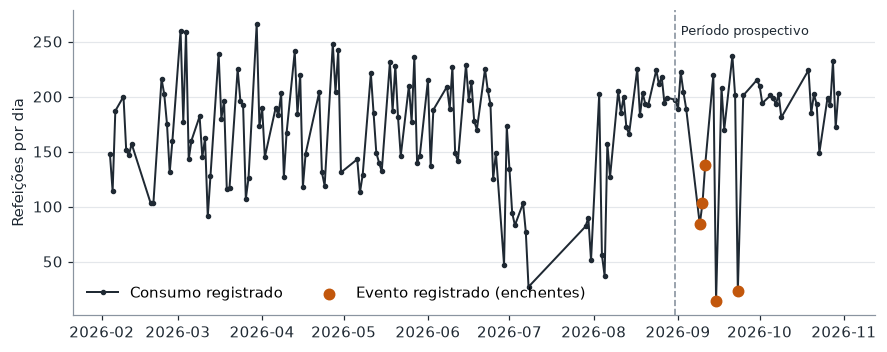

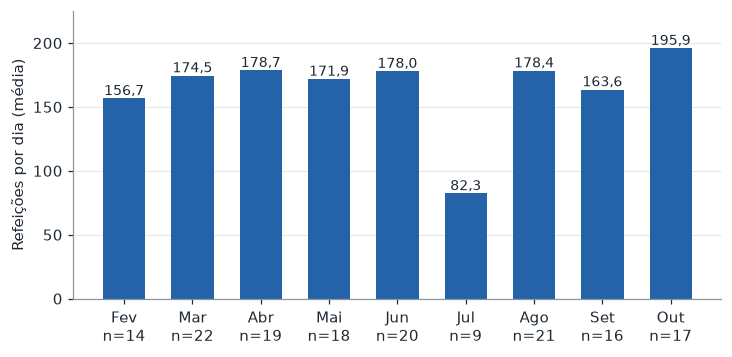

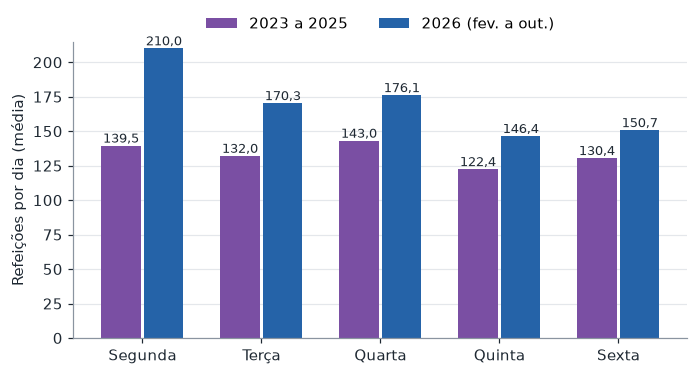

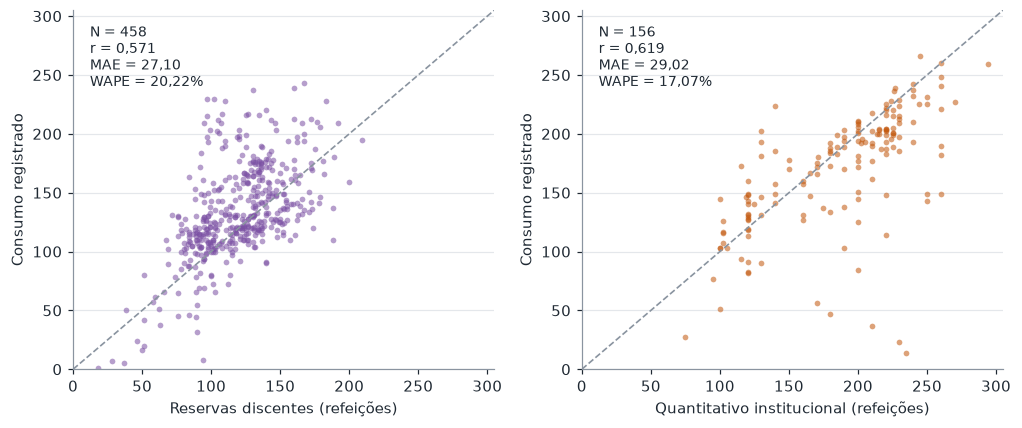

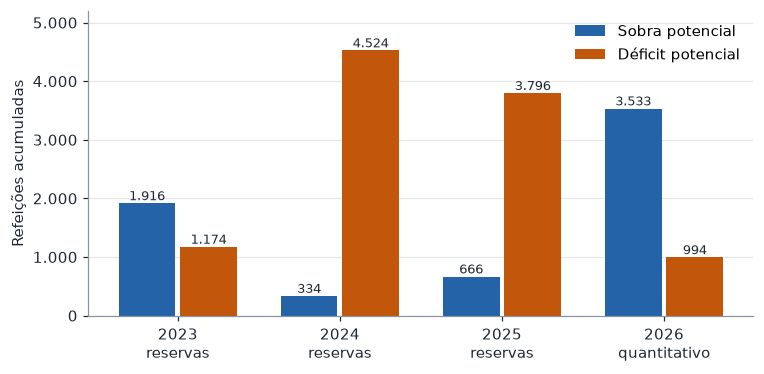

In [6]:
# Figura 15
s26 = a26.sort_values("data")
fig, ax = plt.subplots(figsize=(9.4, 3.6))
ax.plot(s26["data"], s26["consumo"], color=COR_REAL, lw=1.3, marker="o", ms=2.6, label="Consumo registrado")
ev = s26[s26["status_consumo"].eq("atipico")]
ax.scatter(ev["data"], ev["consumo"], s=46, color=COR_NUTRI, zorder=3, label="Evento registrado (enchentes)")
ax.axvline(pd.Timestamp("2026-08-31"), color=COR_NEUTRA, ls="--", lw=1.1)
ax.text(pd.Timestamp("2026-09-02"), s26["consumo"].max(), "Período prospectivo", fontsize=8.5, color=COR_REAL, va="top")
ax.set_ylabel("Refeições por dia"); ax.legend(loc="lower left", ncol=2)
salvar(fig, "figura_15_serie_2026")
NUM["eda_2026"] = {"n": len(a26), "media": float(a26["consumo"].mean()), "min": float(a26["consumo"].min()), "max": float(a26["consumo"].max()),
                   "fev_ago_media": float(a26.loc[a26["data"] <= "2026-08-31", "consumo"].mean()), "set_out_media": float(a26.loc[a26["data"] >= "2026-09-01", "consumo"].mean())}
NUM["eda_dia_2026"] = a26.groupby("dia_semana")["consumo"].mean().round(1).to_dict()
NUM["eda_mes_2026"] = a26.groupby("mes")["consumo"].mean().round(1).to_dict()

# Figura 16
mes26 = a26.groupby("mes")["consumo"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7.6, 3.4))
barras(ax, [f"{MESES[m_]}\nn={int(n)}" for m_, n in zip(mes26.index, mes26["size"])], mes26["mean"].values, COR_IA)
ax.set_ylabel("Refeições por dia (média)"); ax.set_ylim(0, mes26["mean"].max() * 1.15)
salvar(fig, "figura_16_meses_2026")

# Figura 17
fig, ax = plt.subplots(figsize=(7.2, 3.5))
x = np.arange(5); larg = 0.36
d26 = a26.groupby("dia_semana")["consumo"].mean()
d26r = a26[~a26["data"].isin(ATIP)].groupby("dia_semana")["consumo"].mean()
b1 = ax.bar(x - larg / 2, dia_h.values, larg - 0.03, color=COR_RES, label="2023 a 2025")
b2 = ax.bar(x + larg / 2, d26.values, larg - 0.03, color=COR_IA, label="2026 (fev. a out.)")
for r in list(b1) + list(b2):
    ax.text(r.get_x() + r.get_width() / 2, r.get_height(), br(r.get_height(), 1), ha="center", va="bottom", fontsize=8.5, color=COR_REAL)
ax.set_xticks(x); ax.set_xticklabels(DIAS); ax.set_ylabel("Refeições por dia (média)"); ax.set_ylim(0, 215); ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.13))
salvar(fig, "figura_17_comparacao_dias")

# Figura 18
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.0))
for ax, s, col, cor, rot in ((axes[0], s_res, "reserva_discente", COR_RES, "Reservas discentes"), (axes[1], s_nut, "plano_nutricionista", COR_NUTRI, "Quantitativo institucional")):
    lim = 305
    ax.scatter(s[col], s["consumo"], s=14, color=cor, alpha=0.55, linewidths=0)
    ax.plot([0, lim], [0, lim], color=COR_NEUTRA, ls="--", lw=1.1)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_xlabel(f"{rot} (refeições)"); ax.set_ylabel("Consumo registrado")
    q = metricas(s["consumo"], s[col])
    ax.text(0.04, 0.96, f"N = {len(s)}\nr = {br(s['consumo'].corr(s[col]), 3)}\nMAE = {br(q['MAE'])}\nWAPE = {br(q['WAPE'])}%", transform=ax.transAxes, va="top", fontsize=9, color=COR_REAL)
fig.tight_layout(); salvar(fig, "figura_18_metodos_humanos")

# Figura 19
fig, ax = plt.subplots(figsize=(7.8, 3.6))
rot = [f"{int(r.Ano)}\n{'reservas' if r.Ano < 2026 else 'quantitativo'}" for r in regimes.itertuples()]
x = np.arange(len(rot))
b1 = ax.bar(x - 0.19, regimes["Sobra"], 0.35, color=COR_SOBRA, label="Sobra potencial")
b2 = ax.bar(x + 0.19, regimes["Deficit"], 0.35, color=COR_DEFICIT, label="Déficit potencial")
for r in list(b1) + list(b2):
    ax.text(r.get_x() + r.get_width() / 2, r.get_height(), br(r.get_height(), 0), ha="center", va="bottom", fontsize=8.5, color=COR_REAL)
ax.set_xticks(x); ax.set_xticklabels(rot); ax.set_ylabel("Refeições acumuladas"); eixo_br(ax); ax.legend(loc="upper right"); ax.set_ylim(0, regimes[["Sobra", "Deficit"]].max().max() * 1.15)
salvar(fig, "figura_19_sobra_deficit_regimes")

## 5. Treino e teste

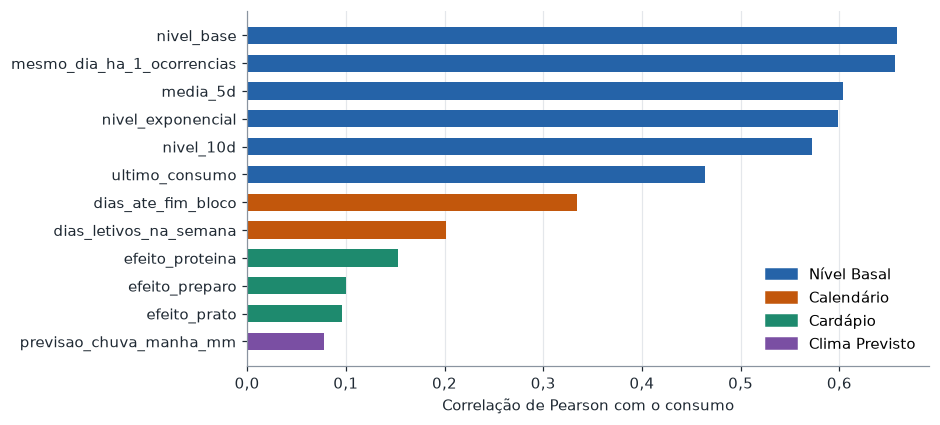

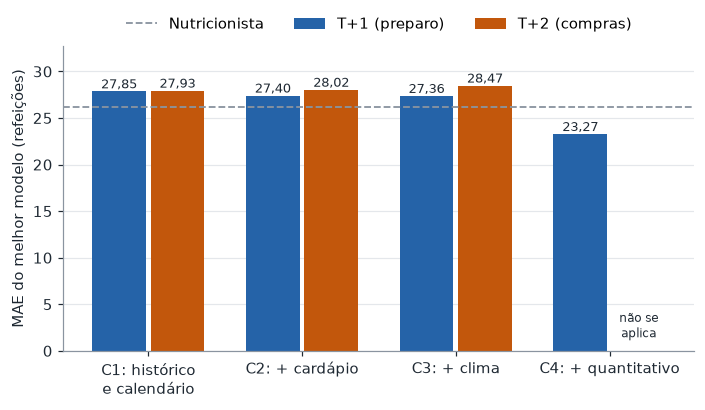

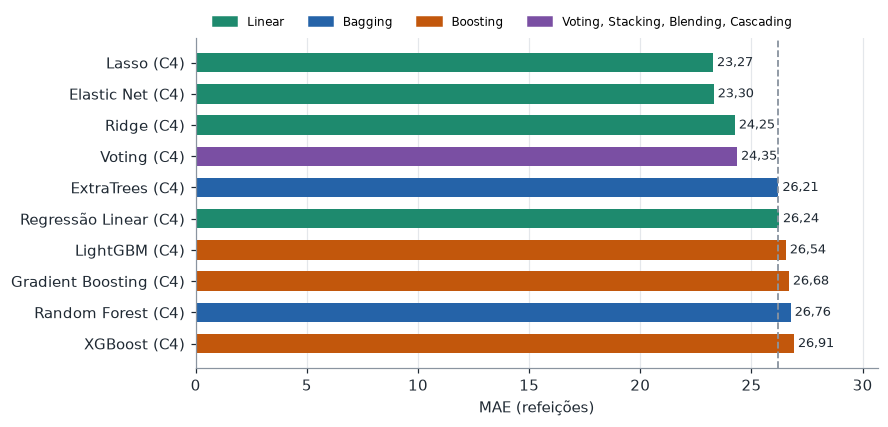

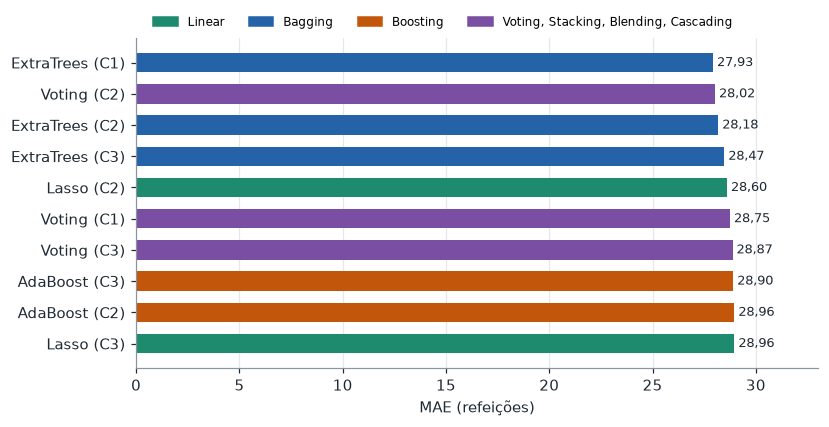

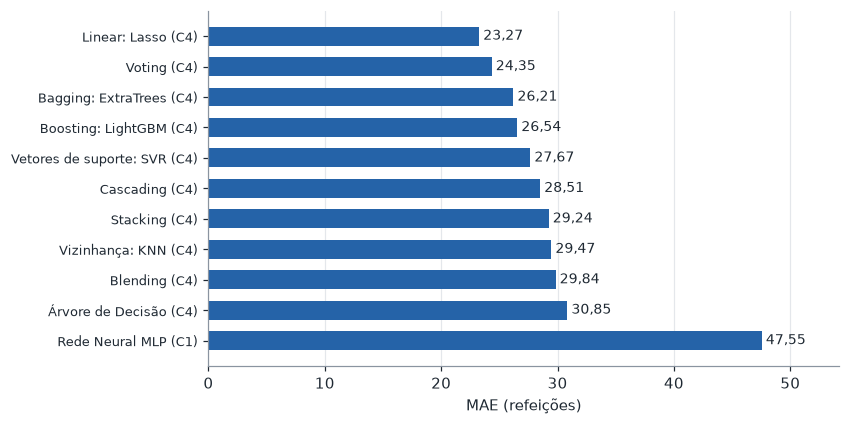

In [7]:
# Figura 20: atributos
rk = pd.read_csv(RESULTADOS / "eda" / "ranking_impacto_atributos.csv", sep=";")
rk = rk[~rk["Grupo"].eq("Clima Oráculo")].sort_values("Corr_Geral", key=np.abs).tail(12)
cor_g = {"Nível Basal": COR_IA, "Calendário": COR_NUTRI, "Cardápio": COR_HIB, "Clima Previsto": COR_RES}
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(rk["Atributo"], rk["Corr_Geral"], color=[cor_g[g] for g in rk["Grupo"]], height=0.62)
ax.grid(False); ax.grid(axis="x", color=COR_GRADE); ax.axvline(0, color=COR_NEUTRA, lw=1); ax.set_xlabel("Correlação de Pearson com o consumo"); eixo_br(ax, "x", 1)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=g) for g, c in cor_g.items()], loc="lower right")
salvar(fig, "figura_20_atributos")
NUM["top_atributos"] = rk.sort_values("Corr_Geral", key=np.abs, ascending=False)[["Atributo", "Corr_Geral"]].head(5).round(3).values.tolist()

# Figura 21: cenários
fig, ax = plt.subplots(figsize=(7.4, 3.6))
ordem = ["C1", "C2", "C3", "C4"]; x = np.arange(4)
v1 = cenarios[cenarios["Horizonte"] == "T+1"].set_index("Cenario").reindex(ordem)["MAE"].values
v2 = cenarios[cenarios["Horizonte"] == "T+2"].set_index("Cenario").reindex(ordem)["MAE"].values
b1 = ax.bar(x - 0.19, v1, 0.35, color=COR_IA, label="T+1 (preparo)")
b2 = ax.bar(x + 0.19, np.nan_to_num(v2), 0.35, color=COR_NUTRI, label="T+2 (compras)")
for r in list(b1) + list(b2):
    if r.get_height() > 0:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height(), br(r.get_height()), ha="center", va="bottom", fontsize=8.5, color=COR_REAL)
ax.text(3 + 0.19, 1, "não se\naplica", ha="center", va="bottom", fontsize=8, color=COR_REAL)
ax.axhline(NUM["regime_nutri_fev_ago"]["MAE"], color=COR_NEUTRA, ls="--", lw=1.2, label="Nutricionista")
ax.set_xticks(x); ax.set_xticklabels(["C1: histórico\ne calendário", "C2: + cardápio", "C3: + clima", "C4: + quantitativo"]); ax.set_ylabel("MAE do melhor modelo (refeições)")
ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.14)); ax.set_ylim(0, max(np.nanmax(v1), np.nanmax(v2)) * 1.15); salvar(fig, "figura_21_cenarios")


def fig_top(tab, nome, ref=None):
    t = tab.iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 3.9))
    rot = [f"{r.Modelo} ({r.Cenario})" for r in t.itertuples()]
    cores = [COR_HIB if r.Familia in ("Linear",) else COR_IA if r.Familia == "Bagging" else COR_NUTRI if r.Familia == "Boosting" else COR_RES for r in t.itertuples()]
    b = ax.barh(rot, t["MAE"], color=cores, height=0.62)
    ax.grid(False); ax.grid(axis="x", color=COR_GRADE)
    for r, v_ in zip(b, t["MAE"]):
        ax.text(v_, r.get_y() + r.get_height() / 2, " " + br(v_), va="center", fontsize=8.8, color=COR_REAL)
    if ref:
        ax.axvline(ref, color=COR_NEUTRA, ls="--", lw=1.2)
    ax.set_xlabel("MAE (refeições)"); ax.set_xlim(0, t["MAE"].max() * 1.14)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=l) for l, c in (("Linear", COR_HIB), ("Bagging", COR_IA), ("Boosting", COR_NUTRI), ("Voting, Stacking, Blending, Cascading", COR_RES))], loc="upper center", ncol=4, bbox_to_anchor=(0.45, 1.1), fontsize=8)
    salvar(fig, nome)


fig_top(top_t1, "figura_22_top10_t1", NUM["regime_nutri_fev_ago"]["MAE"])
fig_top(top_t2, "figura_23_top10_t2")

# Figura 24: famílias
t = familias.iloc[::-1]
fig, ax = plt.subplots(figsize=(7.4, 4.2))
barras(ax, [f"{r.Familia}: {r.Modelo} ({r.Cenario})" if r.Familia.lower() not in r.Modelo.lower() else f"{r.Modelo} ({r.Cenario})" for r in t.itertuples()], t["MAE"].values, COR_IA, 2, True)
ax.set_xlabel("MAE (refeições)"); ax.set_xlim(0, t["MAE"].max() * 1.14); ax.tick_params(axis="y", labelsize=8.2)
salvar(fig, "figura_24_familias")

## 6. Resultados retrospectivos (fevereiro a agosto de 2026)

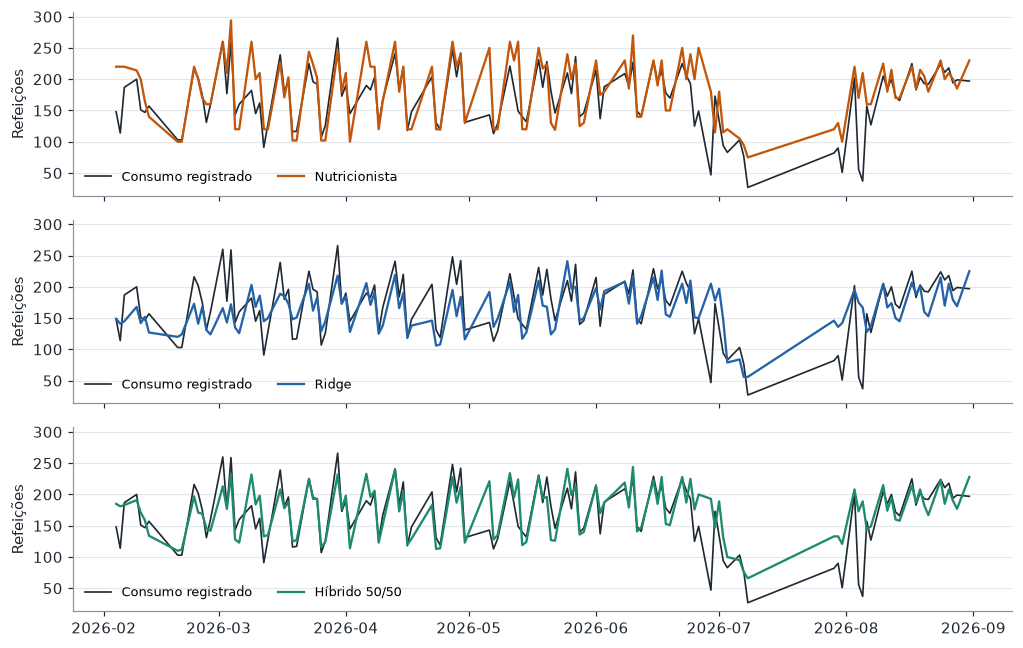

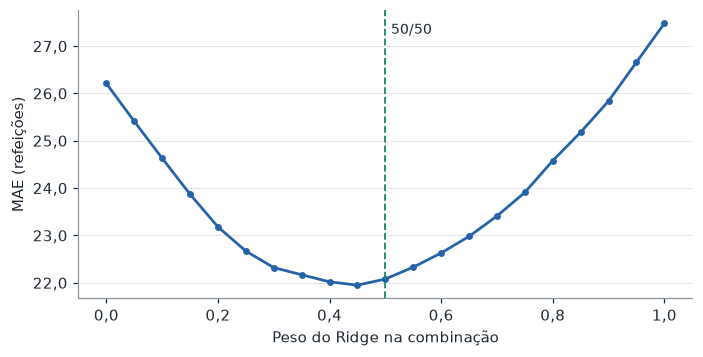

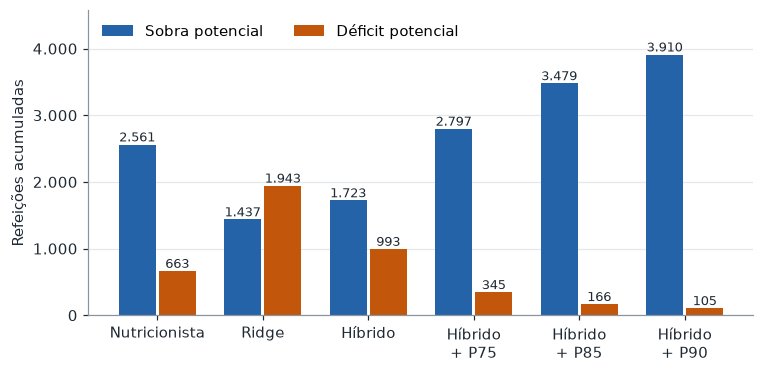

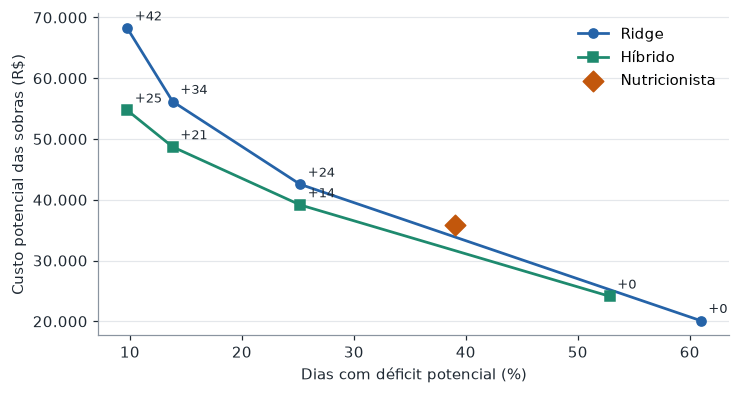

In [8]:
# Figura 25
hib_serie = pd.Series(hi, index=base_fa["data"])
fig, axes = plt.subplots(3, 1, figsize=(9.4, 6.0), sharex=True, sharey=True)
for ax, (nome, p, cor) in zip(axes, (("Nutricionista", nu, COR_NUTRI), (NOME_T1, ia, COR_IA), ("Híbrido 50/50", hi, COR_HIB))):
    ax.plot(base_fa["data"], y, color=COR_REAL, lw=1.1, label="Consumo registrado")
    ax.plot(base_fa["data"], p, color=cor, lw=1.5, label=nome)
    ax.legend(loc="lower left", ncol=2, fontsize=8.5); ax.set_ylabel("Refeições")
fig.tight_layout(); salvar(fig, "figura_25_serie_retrospectiva")

# Figura 26
fr = pd.read_csv(RESULTADOS / "tabelas_dissertacao" / "tabela_fronteira_modelo_hibrido_retrospectivo.csv", sep=";")
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(fr["peso_ia"], fr["MAE"], color=COR_IA, marker="o", ms=3.5)
ax.axvline(0.5, color=COR_HIB, ls="--", lw=1.2); ax.text(0.51, fr["MAE"].max(), "50/50", color=COR_REAL, fontsize=9, va="top")
ax.set_xlabel(f"Peso do {NOME_T1} na combinação"); ax.set_ylabel("MAE (refeições)"); eixo_br(ax, "x", 1); eixo_br(ax, "y", 1)
salvar(fig, "figura_26_fronteira_hibrido")
NUM["fronteira_min"] = fr.sort_values("MAE").iloc[0][["peso_ia", "MAE"]].to_dict()


def fig_sd(tab, nomes, rotulos, arquivo):
    t = tab.set_index("Politica" if "Politica" in tab else "Metodo").loc[nomes]
    x = np.arange(len(nomes))
    fig, ax = plt.subplots(figsize=(7.8, 3.6))
    b1 = ax.bar(x - 0.19, t["Sobra"], 0.35, color=COR_SOBRA, label="Sobra potencial")
    b2 = ax.bar(x + 0.19, t["Deficit"], 0.35, color=COR_DEFICIT, label="Déficit potencial")
    for r in list(b1) + list(b2):
        ax.text(r.get_x() + r.get_width() / 2, r.get_height(), br(r.get_height(), 0), ha="center", va="bottom", fontsize=8.5, color=COR_REAL)
    ax.set_xticks(x); ax.set_xticklabels(rotulos); ax.set_ylabel("Refeições acumuladas"); eixo_br(ax); ax.legend(loc="upper left", ncol=2); ax.set_ylim(0, t[["Sobra", "Deficit"]].max().max() * 1.17)
    salvar(fig, arquivo)


fig_sd(retro, ["Nutricionista", NOME_T1, "Híbrido 50/50", "Híbrido + P75", "Híbrido + P85", "Híbrido + P90"], ["Nutricionista", NOME_T1, "Híbrido", "Híbrido\n+ P75", "Híbrido\n+ P85", "Híbrido\n+ P90"], "figura_27_sobra_deficit_retrospectivo")

# Figura 28
fig, ax = plt.subplots(figsize=(7.4, 3.8))
for nome, cor, mk in ((NOME_T1, COR_IA, "o"), ("Híbrido", COR_HIB, "s")):
    t = retro[retro["Politica"].str.startswith(nome)].sort_values("Margem")
    ax.plot(t["Dias_deficit_pct"], t["Custo"], color=cor, marker=mk, ms=6, label=nome)
    for r in t.itertuples():
        ax.annotate(f"+{int(r.Margem)}", (r.Dias_deficit_pct, r.Custo), xytext=(5, 5), textcoords="offset points", fontsize=8.5, color=COR_REAL)
q = retro[retro["Politica"] == "Nutricionista"].iloc[0]
ax.scatter([q["Dias_deficit_pct"]], [q["Custo"]], s=90, color=COR_NUTRI, marker="D", zorder=3, label="Nutricionista")
ax.set_xlabel("Dias com déficit potencial (%)"); ax.set_ylabel("Custo potencial das sobras (R$)"); eixo_br(ax); ax.legend(loc="upper right")
salvar(fig, "figura_28_tradeoff_retrospectivo")

## 7. Resultados prospectivos (setembro e outubro de 2026)

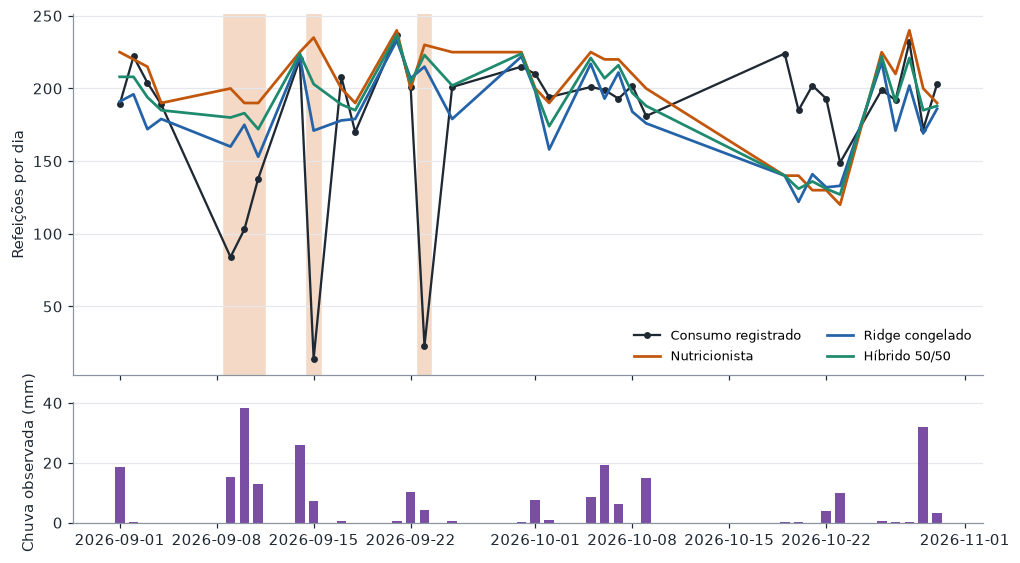

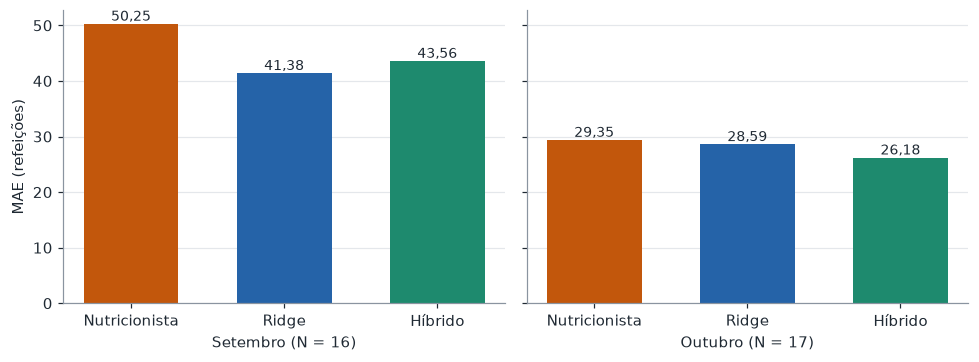

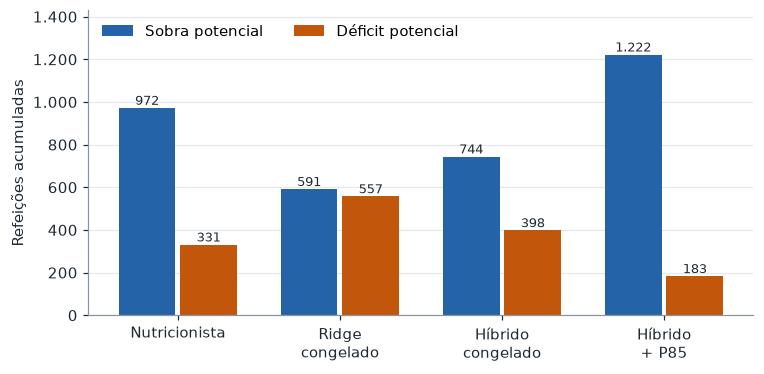

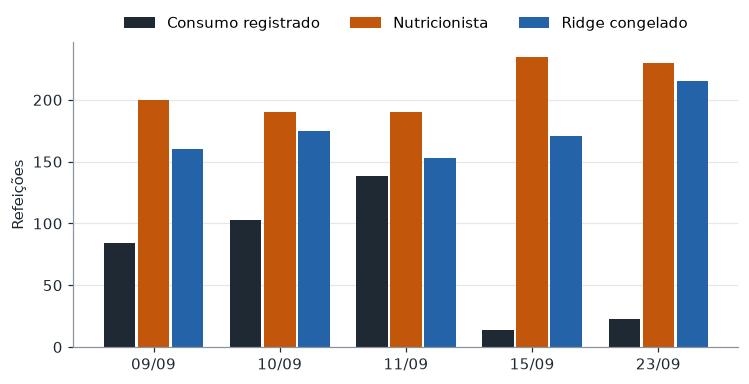

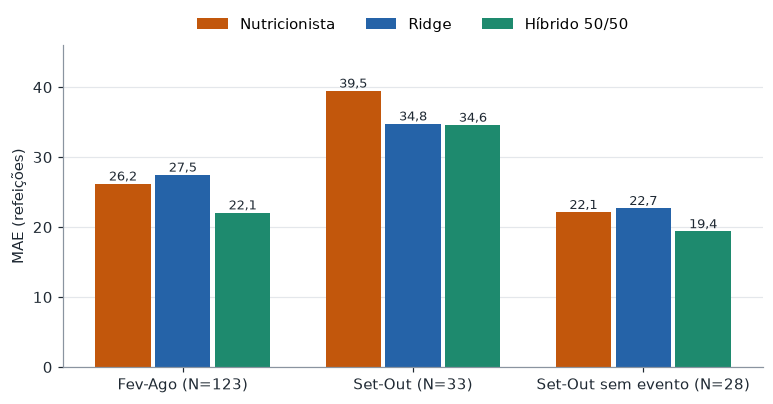

In [9]:
# Figura 29
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9.4, 5.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
a1.plot(te["data"], te["consumo"], color=COR_REAL, marker="o", ms=3.5, lw=1.5, label="Consumo registrado")
a1.plot(te["data"], te["plano_nutricionista"], color=COR_NUTRI, label="Nutricionista")
a1.plot(te["data"], te["previsao_ia"], color=COR_IA, label=f"{NOME_T1} congelado")
a1.plot(te["data"], te["previsao_hibrido"], color=COR_HIB, label="Híbrido 50/50")
for d in te.loc[te["eh_crise_climatica"], "data"]:
    a1.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color="#F3D9C6", zorder=0)
a1.set_ylabel("Refeições por dia"); a1.legend(loc="lower right", ncol=2, fontsize=8.5)
a2.bar(te["data"], te["oraculo_chuva_mm"], color=COR_RES, width=0.7); a2.set_ylabel("Chuva observada (mm)")
fig.tight_layout(); salvar(fig, "figura_29_serie_prospectiva")

# Figura 30
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, rc in zip(axes, ("Setembro", "Outubro")):
    t = prosp[(prosp["Recorte"] == rc) & prosp["Metodo"].isin(["Nutricionista", f"{NOME_T1} congelado", "Híbrido congelado"])]
    bb = ax.bar(["Nutricionista", NOME_T1, "Híbrido"], t["MAE"], color=[COR_NUTRI, COR_IA, COR_HIB], width=0.62)
    for r in bb:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height(), br(r.get_height()), ha="center", va="bottom", fontsize=9, color=COR_REAL)
    ax.set_xlabel(f"{rc} (N = {int(t['n'].iloc[0])})")
axes[0].set_ylabel("MAE (refeições)"); fig.tight_layout(); salvar(fig, "figura_30_meses_prospectivo")

# Figura 31
t33 = prosp[prosp["Recorte"] == "33 dias"]
fig_sd(t33, ["Nutricionista", f"{NOME_T1} congelado", "Híbrido congelado", "Híbrido + P85"], ["Nutricionista", f"{NOME_T1}\ncongelado", "Híbrido\ncongelado", "Híbrido\n+ P85"], "figura_31_sobra_deficit_prospectivo")

# Figura 32
en = te[te["eh_crise_climatica"]]
x = np.arange(len(en)); larg = 0.27
fig, ax = plt.subplots(figsize=(7.8, 3.6))
ax.bar(x - larg, en["consumo"], larg - 0.02, color=COR_REAL, label="Consumo registrado")
ax.bar(x, en["plano_nutricionista"], larg - 0.02, color=COR_NUTRI, label="Nutricionista")
ax.bar(x + larg, en["previsao_ia"], larg - 0.02, color=COR_IA, label=f"{NOME_T1} congelado")
ax.set_xticks(x); ax.set_xticklabels(en["data"].dt.strftime("%d/%m")); ax.set_ylabel("Refeições"); ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.13))
salvar(fig, "figura_32_enchentes")

# Figura 33
fig, ax = plt.subplots(figsize=(8.2, 3.8))
rec = ["Fev-Ago (N=123)", "Set-Out (N=33)", "Set-Out sem evento (N=28)"]
vals = {"Nutricionista": [retro.set_index("Politica").loc["Nutricionista", "MAE"], prosp[(prosp.Recorte == "33 dias") & (prosp.Metodo == "Nutricionista")]["MAE"].iloc[0], prosp[(prosp.Recorte == "28 dias sem evento") & (prosp.Metodo == "Nutricionista")]["MAE"].iloc[0]],
        NOME_T1: [retro.set_index("Politica").loc[NOME_T1, "MAE"], prosp[(prosp.Recorte == "33 dias") & (prosp.Metodo == f"{NOME_T1} congelado")]["MAE"].iloc[0], prosp[(prosp.Recorte == "28 dias sem evento") & (prosp.Metodo == f"{NOME_T1} congelado")]["MAE"].iloc[0]],
        "Híbrido 50/50": [retro.set_index("Politica").loc["Híbrido 50/50", "MAE"], prosp[(prosp.Recorte == "33 dias") & (prosp.Metodo == "Híbrido congelado")]["MAE"].iloc[0], prosp[(prosp.Recorte == "28 dias sem evento") & (prosp.Metodo == "Híbrido congelado")]["MAE"].iloc[0]]}
x = np.arange(3); larg = 0.26
for i, (k, c) in enumerate(zip(vals, (COR_NUTRI, COR_IA, COR_HIB))):
    bb = ax.bar(x + (i - 1) * larg, vals[k], larg - 0.02, color=c, label=k)
    for r in bb:
        ax.text(r.get_x() + r.get_width() / 2, r.get_height(), br(r.get_height(), 1), ha="center", va="bottom", fontsize=8.5, color=COR_REAL)
ax.set_xticks(x); ax.set_xticklabels(rec); ax.set_ylabel("MAE (refeições)"); ax.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.13)); ax.set_ylim(0, 46)
salvar(fig, "figura_33_sintese")

In [10]:
(PASTA_TAB / "numeros_texto.json").write_text(json.dumps(NUM, ensure_ascii=False, indent=2, default=float), encoding="utf-8")
print(sorted(p.name for p in PASTA_FIG.glob("*.png")))

['figura_01_dsr.png', 'figura_02_arquitetura_dados.png', 'figura_03_camadas.png', 'figura_04_validacao_temporal.png', 'figura_05_arquitetura_artefato.png', 'figura_06_fluxo_semanal.png', 'figura_07_perfil_semanal_2023_2025.png', 'figura_08_sazonalidade_2023_2025.png', 'figura_09_proteina_2023_2025.png', 'figura_10_preparo_2023_2025.png', 'figura_11_chuva_2023_2025.png', 'figura_12_temperatura_2023_2025.png', 'figura_13_autocorrelacao_2023_2025.png', 'figura_14_fim_de_semestre_2023_2025.png', 'figura_15_serie_2026.png', 'figura_16_meses_2026.png', 'figura_17_comparacao_dias.png', 'figura_18_metodos_humanos.png', 'figura_19_sobra_deficit_regimes.png', 'figura_20_atributos.png', 'figura_21_cenarios.png', 'figura_22_top10_t1.png', 'figura_23_top10_t2.png', 'figura_24_familias.png', 'figura_25_serie_retrospectiva.png', 'figura_26_fronteira_hibrido.png', 'figura_27_sobra_deficit_retrospectivo.png', 'figura_28_tradeoff_retrospectivo.png', 'figura_29_serie_prospectiva.png', 'figura_30_meses_pr